# Engine mass–Isp trade-offs

Run `./engine_opt --pareto --output-prefix engine` first, then place this notebook beside the generated CSVs. Set `OUTPUT_PREFIX` below if you chose a different path.

Each optimization minimizes mass at one minimum-Isp threshold. The CSV includes only candidates feasible within the driver's constraint tolerance. These are **sampled, stochastic trade-off fronts**, not certified global Pareto fronts. Missing thresholds mean no feasible candidate was found (or a run failed); they do not establish physical infeasibility. `--quick` is only a smoke test.

The plot uses **achieved Isp**, rather than the requested constraint floor. Dominance is evaluated separately for each engine configuration: lower mass and higher Isp are preferred. Connecting lines guide the eye and do not certify the feasibility of intermediate designs.


The turbojet sample requested at **3240 s** is excluded from all plots and front calculations; the source CSV is left intact. The radius figure shows compressor and turbine **outlet shroud radii** for the same mass–Isp front designs, not a separate radius-optimized front. Aft-fan HPT and LPT are shown separately. Radii are in metres.


In [11]:
from pathlib import Path
import csv
import math
import warnings
import matplotlib.pyplot as plt

OUTPUT_PREFIX = Path("build/engine")
ANNOTATE_THRESHOLDS = True
EXPECTED = {
    "aftfan": [3628, 4000, 4500, 4750, 5000, 5250],
    "turbojet": [2429, 2600, 2800, 3000, 3100],
}


In [12]:
csv_path = Path(str(OUTPUT_PREFIX) + "_sweep.csv")
if not csv_path.is_file():
    raise FileNotFoundError(f"Run the optimizer sweep first; missing {csv_path.resolve()}")

with csv_path.open(newline="") as stream:
    reader = csv.DictReader(stream)
    required = {"config", "min_isp_s", "isp_s", "mass_kg"}
    if not required.issubset(reader.fieldnames or []):
        raise ValueError(f"CSV must contain {sorted(required)}")
    rows = []
    excluded_count = 0
    for line_no, record in enumerate(reader, start=2):
        if record["config"] not in EXPECTED:
            raise ValueError(f"Unknown configuration on line {line_no}")
        row = {"config": record["config"]}
        for key in ("min_isp_s", "isp_s", "mass_kg"):
            row[key] = float(record[key])
            if not math.isfinite(row[key]) or row[key] <= 0:
                raise ValueError(f"Invalid {key} on line {line_no}")
        if row["config"] == "turbojet" and math.isclose(row["min_isp_s"], 3240., abs_tol=1e-6, rel_tol=0.):
            excluded_count += 1
            continue
        # Same annulus convention as jet_calc.cpp: R_s = R_m + A/(4*pi*R_m).
        def outlet_shroud(area_column, mean_column):
            try:
                area = float(record[area_column])
                mean = float(record[mean_column])
            except (KeyError, TypeError, ValueError) as error:
                raise ValueError(f"Missing/invalid {area_column} or {mean_column} on line {line_no}; use the full sweep CSV") from error
            if not (math.isfinite(area) and math.isfinite(mean) and area > 0 and mean > 0):
                raise ValueError(f"Invalid outlet geometry on line {line_no}")
            half_span = area / (4 * math.pi * mean)
            if half_span >= mean:
                raise ValueError(f"Nonpositive outlet hub radius on line {line_no}")
            return mean + half_span
        row["compressor_shroud_m"] = outlet_shroud("x6", "x7")
        row["hpt_shroud_m"] = outlet_shroud("x11", "x12")
        if row["config"] == "aftfan":
            row["lpt_shroud_m"] = outlet_shroud("x15", "x16")
        rows.append(row)

print(f"Excluded {excluded_count} turbojet sample(s) with minimum Isp 3240 s")

# Feasibility is checked by the engine evaluator before export. This notebook
# cannot reconstruct all engineering constraints from mass and Isp alone.
for config, thresholds in EXPECTED.items():
    found = {row["min_isp_s"] for row in rows if row["config"] == config}
    missing = [threshold for threshold in thresholds if threshold not in found]
    print(f"{config}: {len(found)}/{len(thresholds)} thresholds returned a feasible candidate")
    if missing:
        warnings.warn(f"{config}: no exported candidate for minimum Isp {missing}")


Excluded 1 turbojet sample(s) with minimum Isp 3240 s
aftfan: 6/6 thresholds returned a feasible candidate
turbojet: 5/5 thresholds returned a feasible candidate


In [13]:
def pareto_front(candidates):
    result = []
    seen = set()
    for row in candidates:
        pair = (row["mass_kg"], row["isp_s"])
        dominated = any(
            other["mass_kg"] <= row["mass_kg"]
            and other["isp_s"] >= row["isp_s"]
            and (other["mass_kg"] < row["mass_kg"] or other["isp_s"] > row["isp_s"])
            for other in candidates
        )
        if not dominated and pair not in seen:
            result.append(row)
            seen.add(pair)
    return sorted(result, key=lambda row: row["isp_s"])

fronts = {
    config: pareto_front([row for row in rows if row["config"] == config])
    for config in EXPECTED
}
for config, front in fronts.items():
    print(f"\n{config} nondominated samples:")
    for row in front:
        print(f"  minimum {row['min_isp_s']:.0f} s → achieved {row['isp_s']:.2f} s, {row['mass_kg']:.4f} kg")



aftfan nondominated samples:
  minimum 3628 s → achieved 3638.90 s, 6.5307 kg
  minimum 4000 s → achieved 4000.00 s, 6.7874 kg
  minimum 4500 s → achieved 4500.00 s, 8.0884 kg
  minimum 4750 s → achieved 4750.00 s, 9.5316 kg
  minimum 5000 s → achieved 5000.00 s, 14.2324 kg
  minimum 5250 s → achieved 5250.00 s, 27.5148 kg

turbojet nondominated samples:
  minimum 2429 s → achieved 2431.44 s, 5.2961 kg
  minimum 2600 s → achieved 2600.00 s, 5.5550 kg
  minimum 2800 s → achieved 2800.00 s, 6.2539 kg
  minimum 3000 s → achieved 3000.00 s, 8.1047 kg
  minimum 3100 s → achieved 3100.00 s, 10.4157 kg


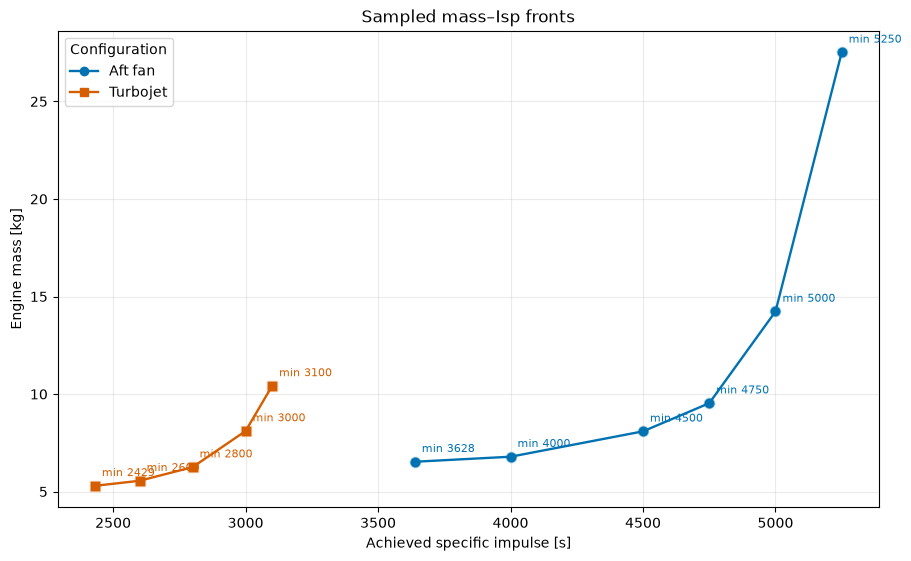

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
styles = {"aftfan": ("Aft fan", "#0072B2", "o"), "turbojet": ("Turbojet", "#D55E00", "s")}
for config, (label, color, marker) in styles.items():
    samples = [row for row in rows if row["config"] == config]
    if samples:
        ax.scatter([r["isp_s"] for r in samples], [r["mass_kg"] for r in samples],
                   color=color, marker=marker, alpha=0.3, s=55)
    front = fronts[config]
    if front:
        ax.plot([r["isp_s"] for r in front], [r["mass_kg"] for r in front],
                color=color, marker=marker, linewidth=1.7, label=label)
        if ANNOTATE_THRESHOLDS:
            for row in front:
                ax.annotate(f"min {row['min_isp_s']:.0f}", (row["isp_s"], row["mass_kg"]),
                            xytext=(5, 7), textcoords="offset points", fontsize=8, color=color)
if not any(fronts.values()):
    ax.text(0.5, 0.5, "No feasible samples exported", transform=ax.transAxes, ha="center")
else:
    ax.legend(title="Configuration")
ax.set(xlabel="Achieved specific impulse [s]", ylabel="Engine mass [kg]",
       title="Sampled mass–Isp fronts")
ax.grid(alpha=0.25)
for suffix in ("png", "pdf"):
    fig.savefig(Path(str(OUTPUT_PREFIX) + f"_fronts.{suffix}"), dpi=180)
plt.show()


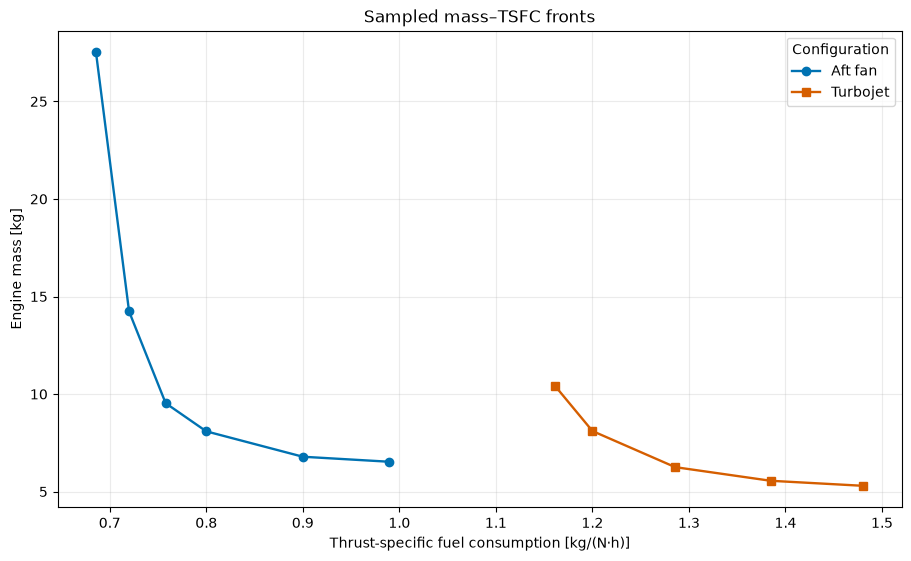

In [18]:
# TSFC [kg/(N·h)] = 3600 / (g * Isp [s])
G = 9.8066

fig_sfc, ax_sfc = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

for config, (label, color, marker) in styles.items():
    front = sorted(fronts[config], key=lambda r: 3600 / ( r["isp_s"]))
    if not front:
        continue

    ax_sfc.plot(
        [3600 / ( r["isp_s"]) for r in front],
        [r["mass_kg"] for r in front],
        color=color, marker=marker, linewidth=1.7, label=label,
    )

    if ANNOTATE_THRESHOLDS:
        for row in front:
            ax_sfc.annotate(
                f"min Isp {row['min_isp_s']:.0f}",
                (3600 / (G * row["isp_s"]), row["mass_kg"]),
                xytext=(5, 7), textcoords="offset points",
                fontsize=8, color=color,
            )

ax_sfc.set(
    xlabel="Thrust-specific fuel consumption [kg/(N·h)]",
    ylabel="Engine mass [kg]",
    title="Sampled mass–TSFC fronts",
)
ax_sfc.grid(alpha=0.25)
if ax_sfc.lines:
    ax_sfc.legend(title="Configuration")

for suffix in ("png", "pdf"):
    fig_sfc.savefig(
        Path(str(OUTPUT_PREFIX) + f"_sfc_fronts.{suffix}"), dpi=180
    )

plt.show()

## Outlet shroud radii along the mass–Isp fronts

The compressor uses `x6` (outlet area) and `x7` (outlet mean radius); HPT uses `x11` and `x12`; LPT uses `x15` and `x16`. The turbojet's single turbine is labelled HPT for comparison. Each shroud radius is reconstructed as

$$R_s = R_m + \frac{A}{4\pi R_m}.$$

These are flow-annulus shroud radii, not casing outer radii or the aft-fan tip radius. Points are selected by mass–Isp dominance, so radius itself need not vary monotonically.


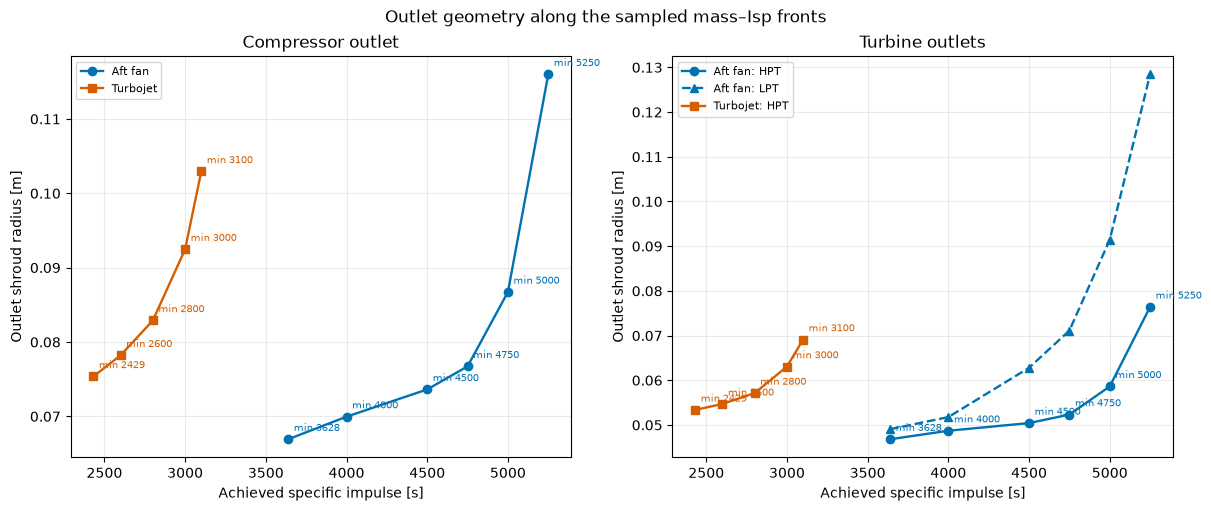

In [15]:
fig_r, (ax_c, ax_t) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, constrained_layout=True)
for config, (label, color, marker) in styles.items():
    front = fronts[config]
    if not front:
        continue
    isp = [row["isp_s"] for row in front]
    ax_c.plot(isp, [row["compressor_shroud_m"] for row in front],
              color=color, marker=marker, linewidth=1.7, label=label)
    ax_t.plot(isp, [row["hpt_shroud_m"] for row in front],
              color=color, marker=marker, linewidth=1.7, label=f"{label}: HPT")
    if config == "aftfan":
        ax_t.plot(isp, [row["lpt_shroud_m"] for row in front],
                  color=color, marker="^", linestyle="--", linewidth=1.7, label="Aft fan: LPT")
    if ANNOTATE_THRESHOLDS:
        for row in front:
            text = f"min {row['min_isp_s']:.0f}"
            ax_c.annotate(text, (row["isp_s"], row["compressor_shroud_m"]),
                          xytext=(4, 6), textcoords="offset points", fontsize=7, color=color)
            ax_t.annotate(text, (row["isp_s"], row["hpt_shroud_m"]),
                          xytext=(4, 6), textcoords="offset points", fontsize=7, color=color)
for ax, title in ((ax_c, "Compressor outlet"), (ax_t, "Turbine outlets")):
    ax.set(xlabel="Achieved specific impulse [s]", ylabel="Outlet shroud radius [m]", title=title)
    ax.grid(alpha=0.25)
    if ax.lines:
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "No feasible samples exported", transform=ax.transAxes, ha="center")
fig_r.suptitle("Outlet geometry along the sampled mass–Isp fronts")
for suffix in ("png", "pdf"):
    fig_r.savefig(Path(str(OUTPUT_PREFIX) + f"_shroud_radii.{suffix}"), dpi=180)
plt.show()
